# Subquestion 4
Is the extension of the free student travel product to MBO students under 18 (1 January 2017) associated with an increase in train and bus/tram/metro use among 12–18 year olds, compared with 18–25 year olds?

In [2]:
# Loading packages
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.io as pio
import numpy as np
import nbformat
idx = pd.IndexSlice

In [3]:
# Loading the data sets
path2 = '../Data_age_research/2_Mobility_per_person_by_transport_mode_and_purpose_(84710NED).csv'
path4 = '../Data_age_research/4_Mobility_per_person_by_personal_characteristics_(84709NED).csv'

data_set2 = pd.read_csv(path2, sep=";", decimal=',', skiprows=5, header=[0, 1, 2, 3], index_col=0, skipfooter=1, na_values=['.', ''], engine='python')
data_set4 = pd.read_csv(path4, sep=';', decimal=',', skiprows=7, header=[0, 1, 2], index_col=0, na_values=['.', ''], engine='python')

In [4]:
# display(data_set2)

agegroups = ['12 tot 18 jaar', '18 tot 25 jaar']
transportmode = ['Trein', 'Bus/tram/metro']

data2_filtered = data_set2.loc[:, idx[agegroups, transportmode, 'Totaal', :]]
display(data2_filtered)

Leeftijd      12 tot 18 jaar                18 tot 25 jaar               
Vervoerwijzen          Trein Bus/tram/metro          Trein Bus/tram/metro
Reismotieven          Totaal         Totaal         Totaal         Totaal
Perioden              aantal         aantal         aantal         aantal
1999*                   0.07           0.23           0.21           0.43
2000*                   0.07           0.22           0.22           0.43
2001*                   0.07           0.22           0.22           0.42
2002*                   0.07           0.21           0.21           0.41
2003*                   0.07           0.20           0.21           0.41
2004*                   0.06           0.20           0.21           0.40
2005*                   0.06           0.19           0.22           0.40
2006*                   0.06           0.19           0.22           0.40
2007*                   0.06           0.19           0.23           0.40
2008*                   0.06           0.18           0.23           0.39
2009*                   0.06           0.18           0.23           0.40
2010*                   0.06           0.18           0.23           0.40
2011*                   0.06           0.18           0.24           0.40
2012*                   0.06           0.17           0.24           0.39
2013*                   0.06           0.18           0.25           0.40
2014*                   0.06           0.18           0.25           0.39
2015*                   0.06           0.18           0.25           0.39
2016*                   0.07           0.18           0.24           0.39
2017*                   0.07           0.18           0.25           0.39
2018*                   0.07           0.19           0.24           0.38
2019*                   0.07           0.18           0.25           0.38
2020*                   0.03           0.10           0.13           0.20
2021*                   0.04           0.11           0.14           0.21
2022*                   0.05           0.14           0.18           0.27
2023*                   0.06           0.15           0.20           0.31
2024*                   0.06           0.16           0.21           0.31
2025*                   0.06           0.15           0.21           0.31

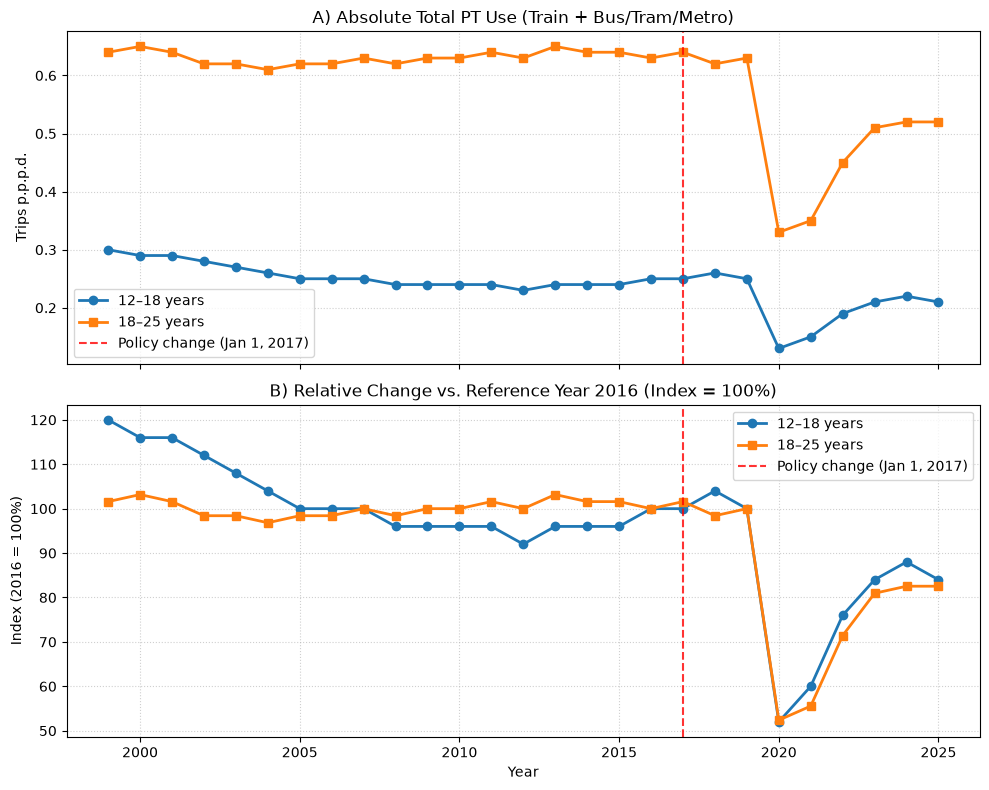

In [5]:
# Clean index years
data_set2.index = data_set2.index.str.replace('*', '', regex=False).astype(int)

idx = pd.IndexSlice
age_groups = ['12 tot 18 jaar', '18 tot 25 jaar']

# Filter the data
df2_train = data_set2.loc[:, idx[age_groups, 'Trein', 'Totaal', 'aantal']]
df2_btm = data_set2.loc[:, idx[age_groups, 'Bus/tram/metro', 'Totaal', 'aantal']]

# Simplify column names to age group level
df2_train.columns = df2_train.columns.get_level_values('Leeftijd')
df2_btm.columns = df2_btm.columns.get_level_values('Leeftijd')

# Calculate total public transport (PT) use
df2_total_pt = df2_train + df2_btm

# Index values relative to 2016 (2016 = 100%)
df2_indexed = (df2_total_pt / df2_total_pt.loc[2016]) * 100

# Create figure with 2 stacked subplots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Subplot A: Absolute numbers
ax1.plot(df2_total_pt.index, df2_total_pt['12 tot 18 jaar'], label='12–18 years', marker='o', color='#1f77b4', linewidth=2)
ax1.plot(df2_total_pt.index, df2_total_pt['18 tot 25 jaar'], label='18–25 years', marker='s', color='#ff7f0e', linewidth=2)
ax1.axvline(x=2017, color='red', linestyle='--', alpha=0.8, label='Policy change (Jan 1, 2017)')
ax1.set_ylabel('Trips p.p.p.d.')
ax1.set_title('A) Absolute Total PT Use (Train + Bus/Tram/Metro)')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='best')

# Subplot B: Indexed trend (2016 = 100%)
ax2.plot(df2_indexed.index, df2_indexed['12 tot 18 jaar'], label='12–18 years', marker='o', color='#1f77b4', linewidth=2)
ax2.plot(df2_indexed.index, df2_indexed['18 tot 25 jaar'], label='18–25 years', marker='s', color='#ff7f0e', linewidth=2)
ax2.axvline(x=2017, color='red', linestyle='--', alpha=0.8, label='Policy change (Jan 1, 2017)')
ax2.set_ylabel('Index (2016 = 100%)')
ax2.set_xlabel('Year')
ax2.set_title('B) Relative Change vs. Reference Year 2016 (Index = 100%)')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='best')

plt.tight_layout()
plt.show()